# Практическая работа №3. Разработка и сравнительный анализ ансамблевых методов машинного обучения
**Вариант 5.** Датасет: Dry Bean Dataset (UCI Machine Learning Repository). Задача: многоклассовая классификация сортов сухой фасоли (7 классов). Модели: базовая Decision Tree; ансамбли Bagging, Random Forest, AdaBoost, Gradient Boosting.

## Этап 1. Подбор и загрузка датасета

In [1]:
import os, time, io, zipfile, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); os.makedirs('fig', exist_ok=True)
def save(n): plt.tight_layout(); plt.savefig(f'fig/{n}.png', dpi=150, bbox_inches='tight'); plt.show()

CSV = 'Dry_Bean_Dataset.csv'
if not os.path.exists(CSV):   # в Colab датасет скачивается с UCI автоматически
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen('https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip').read()))
    pd.read_excel(z.open('DryBeanDataset/Dry_Bean_Dataset.xlsx')).to_csv(CSV, index=False)
df = pd.read_csv(CSV)
print('Количество объектов:', df.shape[0]); print('Количество признаков (с целевой):', df.shape[1])

Количество объектов: 13611
Количество признаков (с целевой): 17


In [2]:
num_cols = df.select_dtypes(include='number').columns.tolist()
print('Числовые признаки (%d):' % len(num_cols), num_cols)
print('Категориальные признаки:', [c for c in df.columns if c not in num_cols])
print('Тип задачи: многоклассовая классификация; целевая переменная: Class')

Числовые признаки (16): ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']
Категориальные признаки: ['Class']
Тип задачи: многоклассовая классификация; целевая переменная: Class


## Этап 2. Исследовательский анализ данных (EDA)

In [3]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
df.tail()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON
13610,42159,772.237,295.142741,182.204716,1.619841,0.786693,42600,231.686223,0.788962,0.989648,0.888380,0.784997,0.007001,0.001640,0.616221,0.998180,DERMASON


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [6]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.285,29324.096,20420.000,36328.000,44652.000,61332.000,254616.000
Perimeter,13611.0,855.283,214.290,524.736,703.523,794.941,977.213,1985.370
MajorAxisLength,13611.0,320.142,85.694,183.601,253.304,296.883,376.495,738.860
MinorAxisLength,13611.0,202.271,44.970,122.513,175.848,192.432,217.032,460.198
AspectRation,13611.0,1.583,0.247,1.025,1.432,1.551,1.707,2.430
Eccentricity,13611.0,0.751,0.092,0.219,0.716,0.764,0.810,0.911
ConvexArea,13611.0,53768.200,29774.916,20684.000,36714.500,45178.000,62294.000,263261.000
EquivDiameter,13611.0,253.064,59.177,161.244,215.068,238.438,279.446,569.374
Extent,13611.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13611.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


In [7]:
print('Пропущенные значения:', int(df.isna().sum().sum()))
print('Дубликатов:', df.duplicated().sum())
print('\nАсимметрия признаков:'); print(df[num_cols].skew().round(2).sort_values())

Пропущенные значения: 0
Дубликатов: 68

Асимметрия признаков:
ShapeFactor4      -2.76
Solidity          -2.55
Eccentricity      -1.06
Extent            -0.90
roundness         -0.64
ShapeFactor1      -0.53
Compactness        0.04
ShapeFactor3       0.24
ShapeFactor2       0.30
AspectRation       0.58
MajorAxisLength    1.36
Perimeter          1.63
EquivDiameter      1.95
MinorAxisLength    2.24
ConvexArea         2.94
Area               2.95
dtype: float64


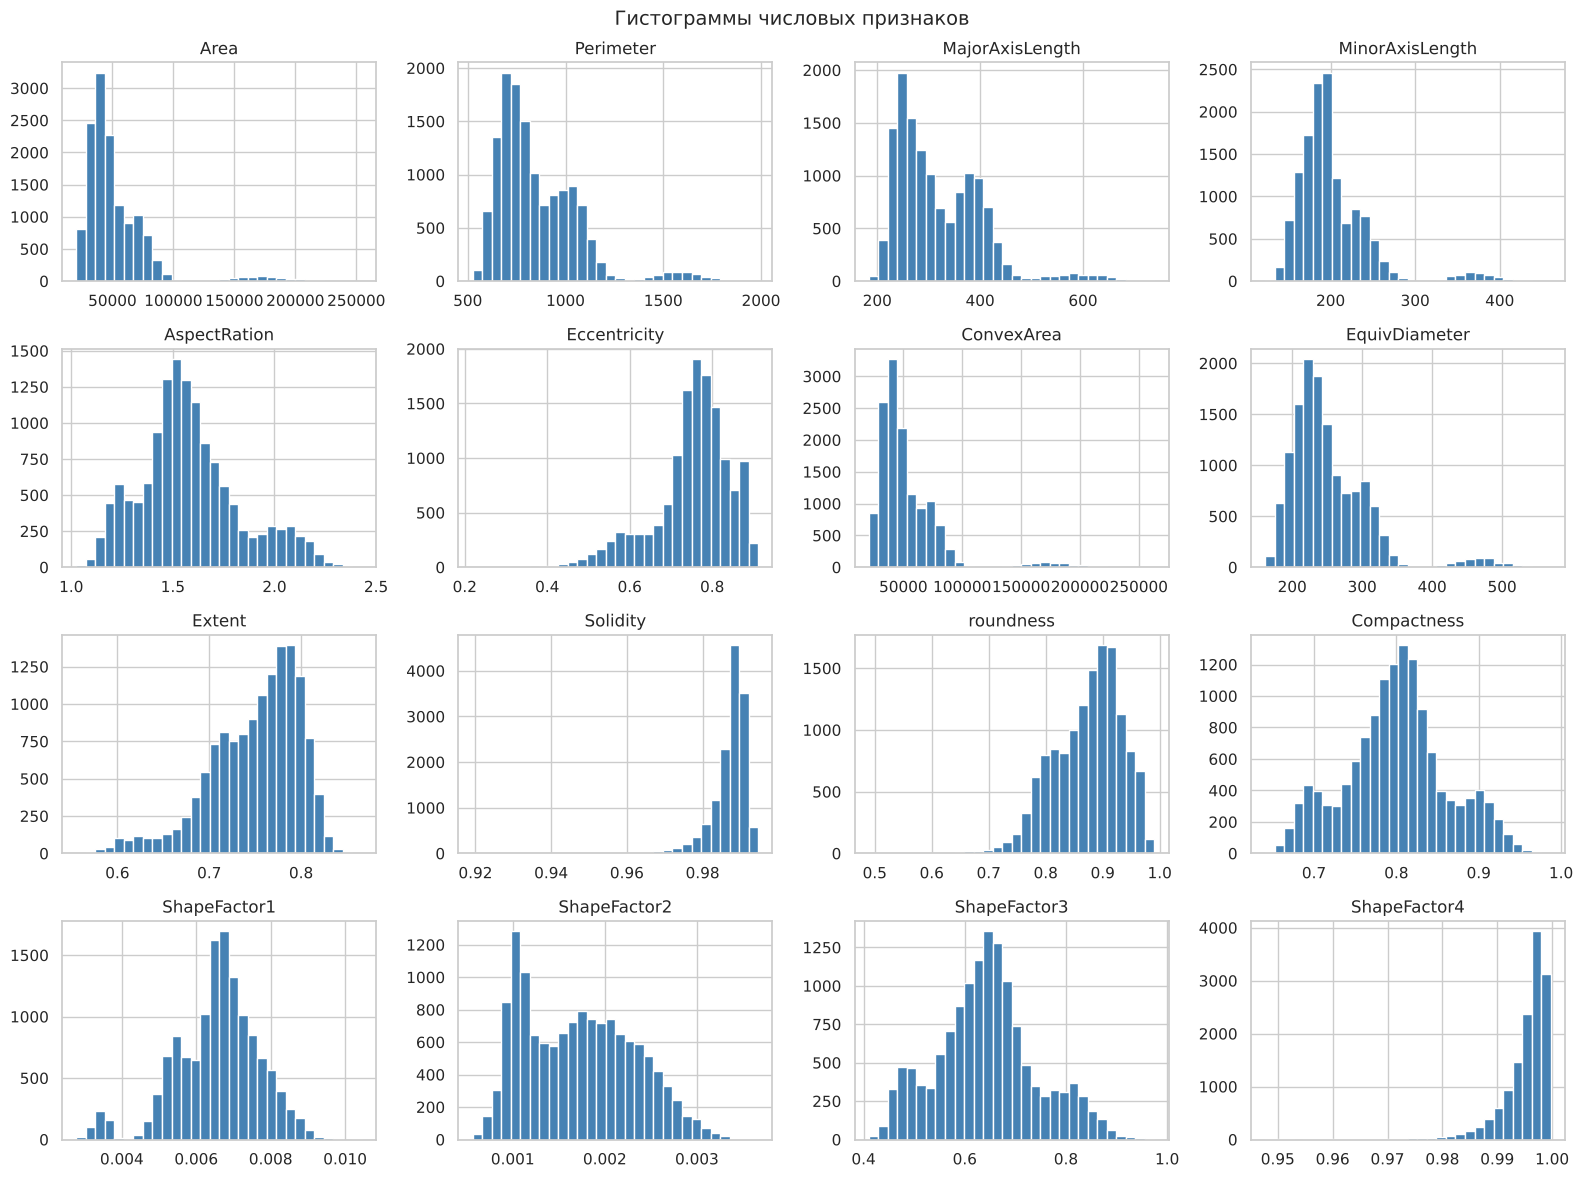

In [8]:
df[num_cols].hist(bins=30, figsize=(16, 12), color='steelblue', edgecolor='white'); plt.suptitle('Гистограммы числовых признаков', fontsize=14); save('hist')

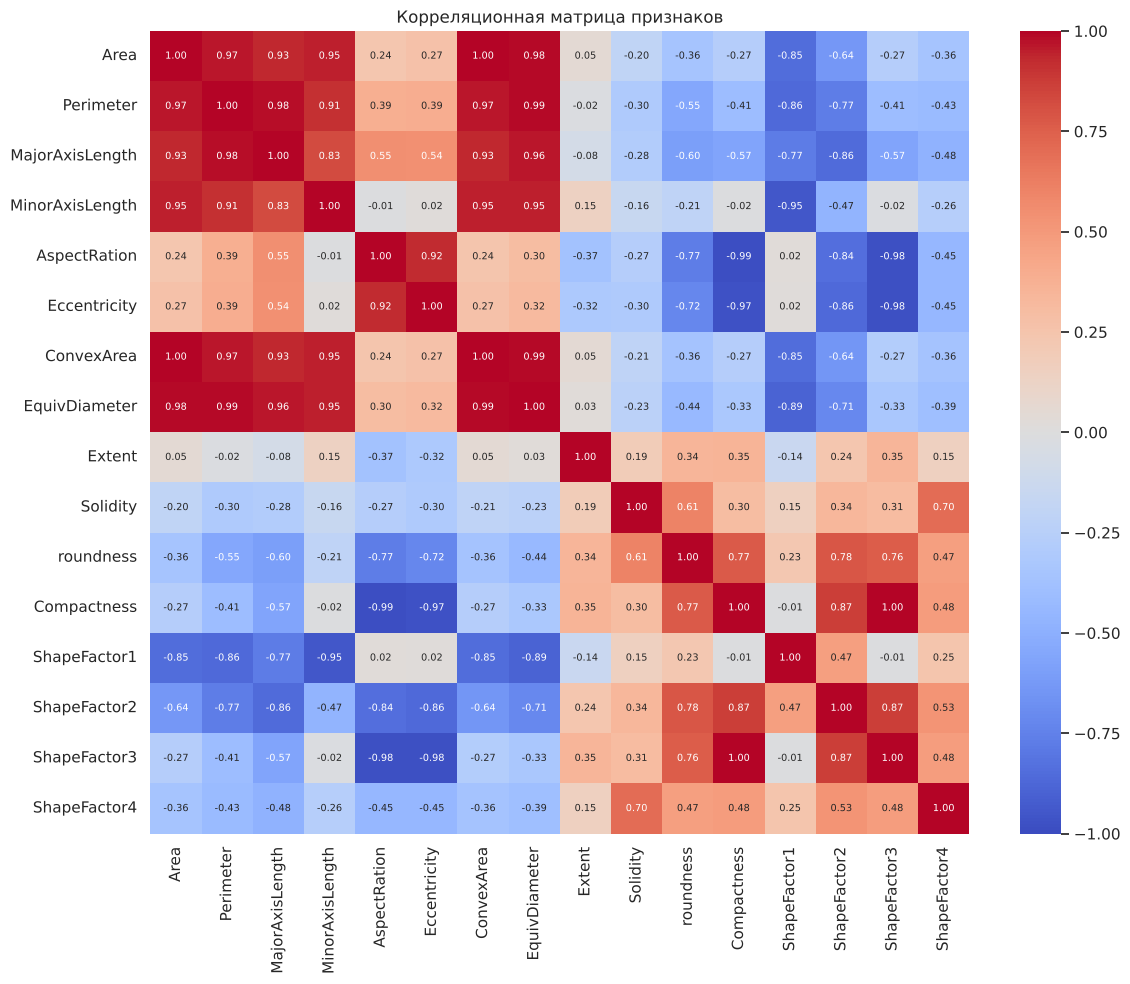

In [9]:
plt.figure(figsize=(12, 10)); sns.heatmap(df[num_cols].corr(), cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Корреляционная матрица признаков'); save('corr')

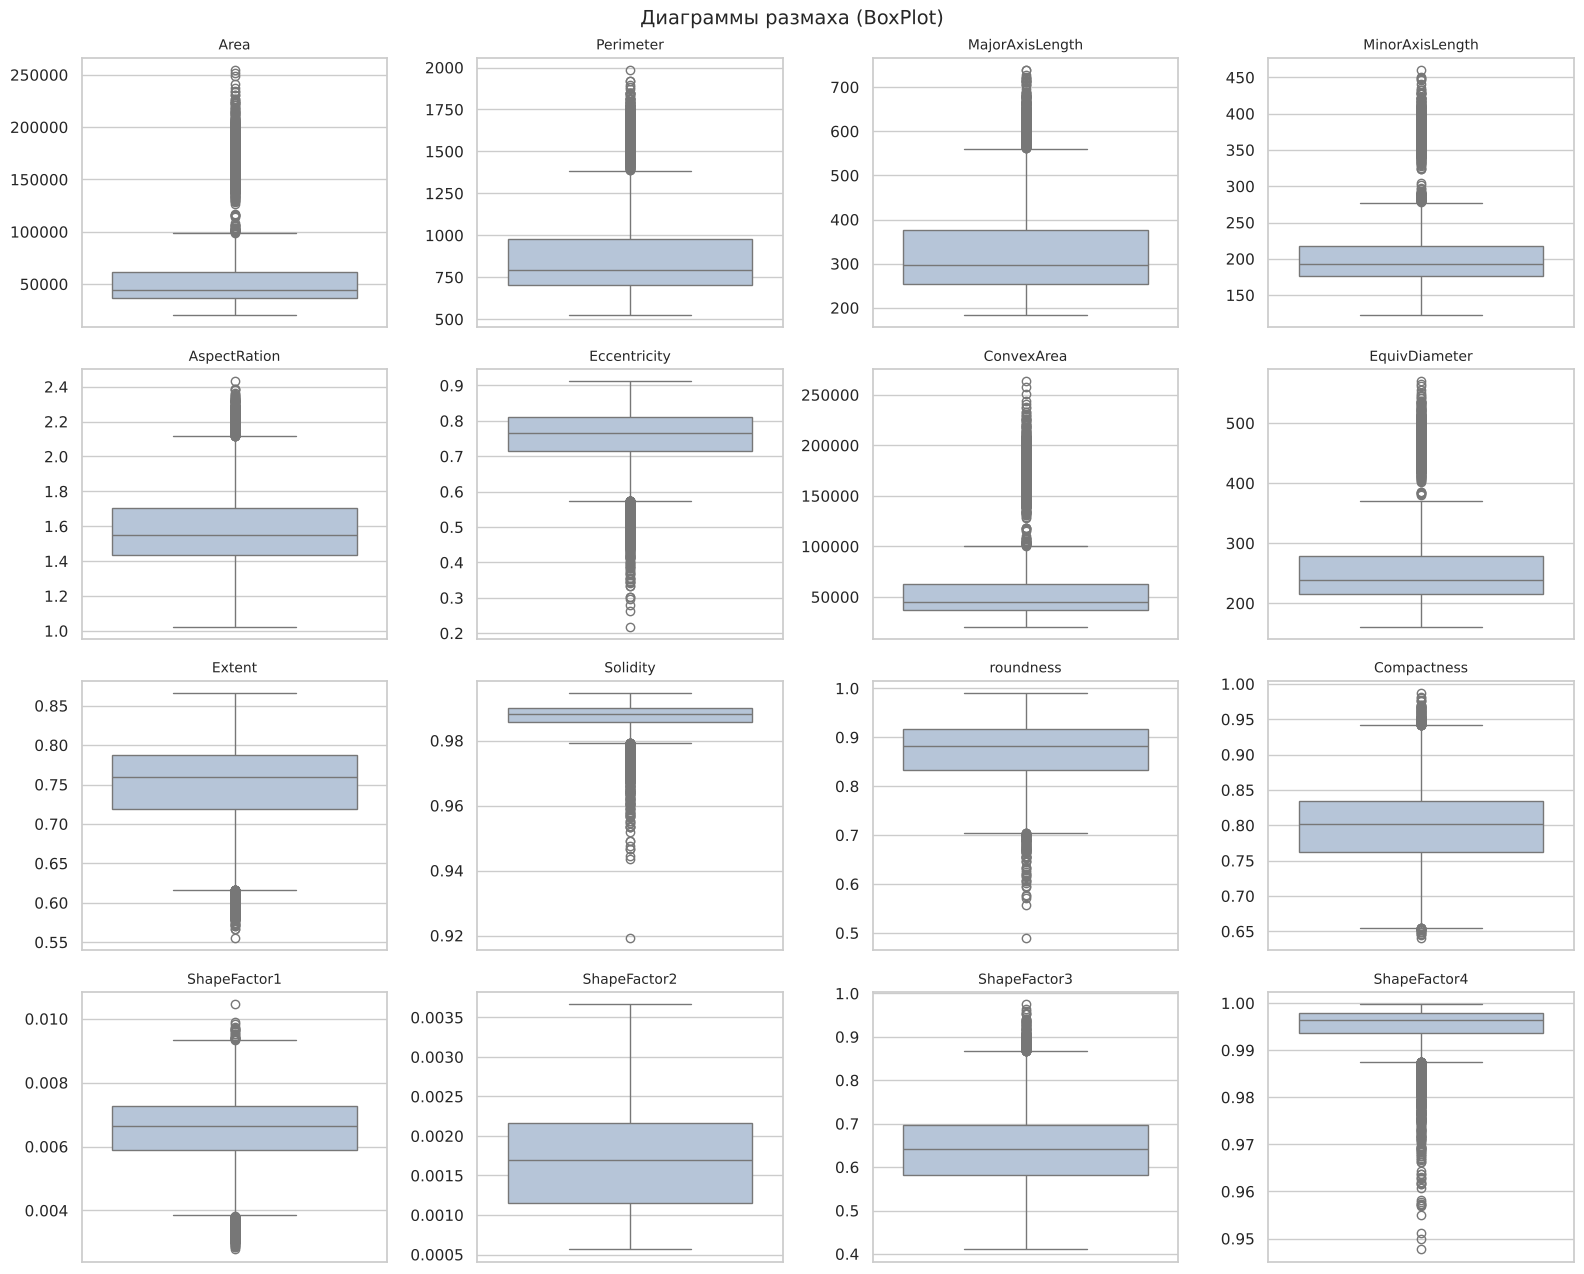

Выбросы по правилу 1.5·IQR:
Eccentricity       843
Solidity           778
ShapeFactor4       767
MinorAxisLength    569
Area               551
ConvexArea         550
ShapeFactor1       533
EquivDiameter      526
Perimeter          500
AspectRation       473
MajorAxisLength    379
Extent             275
ShapeFactor3       195
Compactness        109
roundness           91
ShapeFactor2         0
dtype: int64


In [10]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, c in zip(axes.ravel(), num_cols): sns.boxplot(y=df[c], ax=ax, color='lightsteelblue'); ax.set_title(c, fontsize=10); ax.set_ylabel('')
plt.suptitle('Диаграммы размаха (BoxPlot)', fontsize=14); save('box')
iqr = lambda s: ((s < s.quantile(.25) - 1.5*(s.quantile(.75)-s.quantile(.25))) | (s > s.quantile(.75) + 1.5*(s.quantile(.75)-s.quantile(.25)))).sum()
print('Выбросы по правилу 1.5·IQR:'); print(df[num_cols].apply(iqr).sort_values(ascending=False))

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Доля, %:
Class
DERMASON    26.1
SIRA        19.4
SEKER       14.9
HOROZ       14.2
CALI        12.0
BARBUNYA     9.7
BOMBAY       3.8
Name: count, dtype: float64


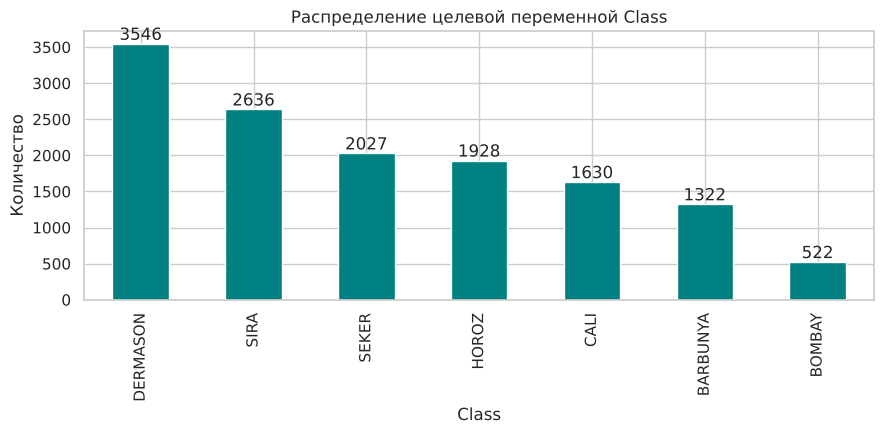

In [11]:
vc = df['Class'].value_counts(); print(vc); print('\nДоля, %:'); print((vc / len(df) * 100).round(1))
plt.figure(figsize=(9, 4.5)); ax = vc.plot.bar(color='teal'); plt.title('Распределение целевой переменной Class'); plt.ylabel('Количество')
for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
save('target')

**Выводы по EDA.** 13 611 объектов, 16 числовых признаков (геометрия зерна по изображению) и целевая переменная Class с 7 сортами. Пропусков нет, есть 68 полных дубликатов. Многие признаки сильно коррелируют (Area, Perimeter, ConvexArea, EquivDiameter, MajorAxisLength — 0,9 и выше), так как описывают размер зерна. Выбросы есть почти во всех признаках, но это реальные крупные и мелкие зерна (особенно сорт BOMBAY), поэтому они не удаляются. Классы несбалансированы: DERMASON — 26 %, BOMBAY — 3,8 %, поэтому применяется стратифицированное разбиение и макро-усреднение метрик.

## Этап 3. Предварительная обработка данных

In [12]:
df = df.drop_duplicates().reset_index(drop=True); print('После удаления дубликатов:', df.shape)
X = df[num_cols]; le = LabelEncoder(); y = le.fit_transform(df['Class'])
print('Кодирование классов:', dict(zip(le.classes_, range(len(le.classes_)))))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train); X_train_s = scaler.transform(X_train); X_test_s = scaler.transform(X_test)
print('Обучающая выборка:', X_train.shape, ' тестовая:', X_test.shape)

После удаления дубликатов: (13543, 17)
Кодирование классов: {'BARBUNYA': 0, 'BOMBAY': 1, 'CALI': 2, 'DERMASON': 3, 'HOROZ': 4, 'SEKER': 5, 'SIRA': 6}
Обучающая выборка: (10834, 16)  тестовая: (2709, 16)


Масштабирование выполнено StandardScaler по обучающей выборке (для деревьев не обязательно, но не ухудшает результат и делает конвейер единым). Стратификация сохраняет доли классов в обеих выборках.

## Этап 4. Построение базовой модели (Decision Tree)

In [13]:
results, preds, probas, models = [], {}, {}, {}
def evaluate(name, model):
    t0 = time.perf_counter(); model.fit(X_train_s, y_train); tf = time.perf_counter() - t0
    t0 = time.perf_counter(); p = model.predict(X_test_s); tp = time.perf_counter() - t0
    pr = model.predict_proba(X_test_s); preds[name], probas[name], models[name] = p, pr, model
    results.append({'Модель': name, 'Accuracy': accuracy_score(y_test, p),
        'Precision': precision_score(y_test, p, average='macro'), 'Recall': recall_score(y_test, p, average='macro'),
        'F1-score': f1_score(y_test, p, average='macro'), 'ROC-AUC': roc_auc_score(y_test, pr, multi_class='ovr', average='macro'),
        'Обучение, с': tf, 'Прогноз, с': tp})
    print(f"{name}: Accuracy={results[-1]['Accuracy']:.4f}, F1(macro)={results[-1]['F1-score']:.4f}, время обучения {tf:.2f} с")
evaluate('Decision Tree', DecisionTreeClassifier(max_depth=10, min_samples_leaf=5, random_state=42))

Decision Tree: Accuracy=0.9070, F1(macro)=0.9211, время обучения 0.14 с


## Этап 5. Построение и обучение ансамблевых моделей

In [14]:
evaluate('Bagging', BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42), n_estimators=100, n_jobs=-1, random_state=42))
evaluate('Random Forest', RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42))
evaluate('AdaBoost', AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3, random_state=42), n_estimators=200, learning_rate=0.5, random_state=42))
evaluate('Gradient Boosting', GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=42))
pd.DataFrame({k: le.inverse_transform(v) for k, v in preds.items()}).assign(Истина=le.inverse_transform(y_test)).to_csv('predictions.csv', index=False)

Bagging: Accuracy=0.9136, F1(macro)=0.9269, время обучения 4.20 с


Random Forest: Accuracy=0.9199, F1(macro)=0.9310, время обучения 2.29 с


AdaBoost: Accuracy=0.9055, F1(macro)=0.9193, время обучения 11.28 с


Gradient Boosting: Accuracy=0.9147, F1(macro)=0.9269, время обучения 64.63 с


## Этап 6. Оценка качества моделей

In [15]:
res = pd.DataFrame(results).set_index('Модель'); res.round(4).to_csv('metrics.csv'); res.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,"Обучение, с","Прогноз, с"
Модель,,,,,,,
Decision Tree,0.9070,0.9220,0.9204,0.9211,0.9779,0.1370,0.0007
Bagging,0.9136,0.9280,0.9260,0.9269,0.9901,4.1975,0.0639
Random Forest,0.9199,0.9322,0.9300,0.9310,0.9933,2.2905,0.0975
AdaBoost,0.9055,0.9183,0.9203,0.9193,0.9835,11.2826,0.0805
Gradient Boosting,0.9147,0.9292,0.9248,0.9269,0.9938,64.6294,0.0466


In [16]:
for n in ['Decision Tree', 'Gradient Boosting']:
    print(f'=== {n} ==='); print(classification_report(y_test, preds[n], target_names=le.classes_, digits=3))

=== Decision Tree ===
              precision    recall  f1-score   support

    BARBUNYA      0.919     0.902     0.910       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.905     0.933     0.918       326
    DERMASON      0.903     0.903     0.903       709
       HOROZ      0.966     0.919     0.942       372
       SEKER      0.923     0.938     0.930       406
        SIRA      0.839     0.848     0.843       527

    accuracy                          0.907      2709
   macro avg      0.922     0.920     0.921      2709
weighted avg      0.908     0.907     0.907      2709

=== Gradient Boosting ===
              precision    recall  f1-score   support

    BARBUNYA      0.925     0.883     0.903       265
      BOMBAY      1.000     1.000     1.000       104
        CALI      0.924     0.939     0.932       326
    DERMASON      0.899     0.925     0.912       709
       HOROZ      0.951     0.935     0.943       372
       SEKER      0.946     0.

## Этап 7. Визуализация результатов

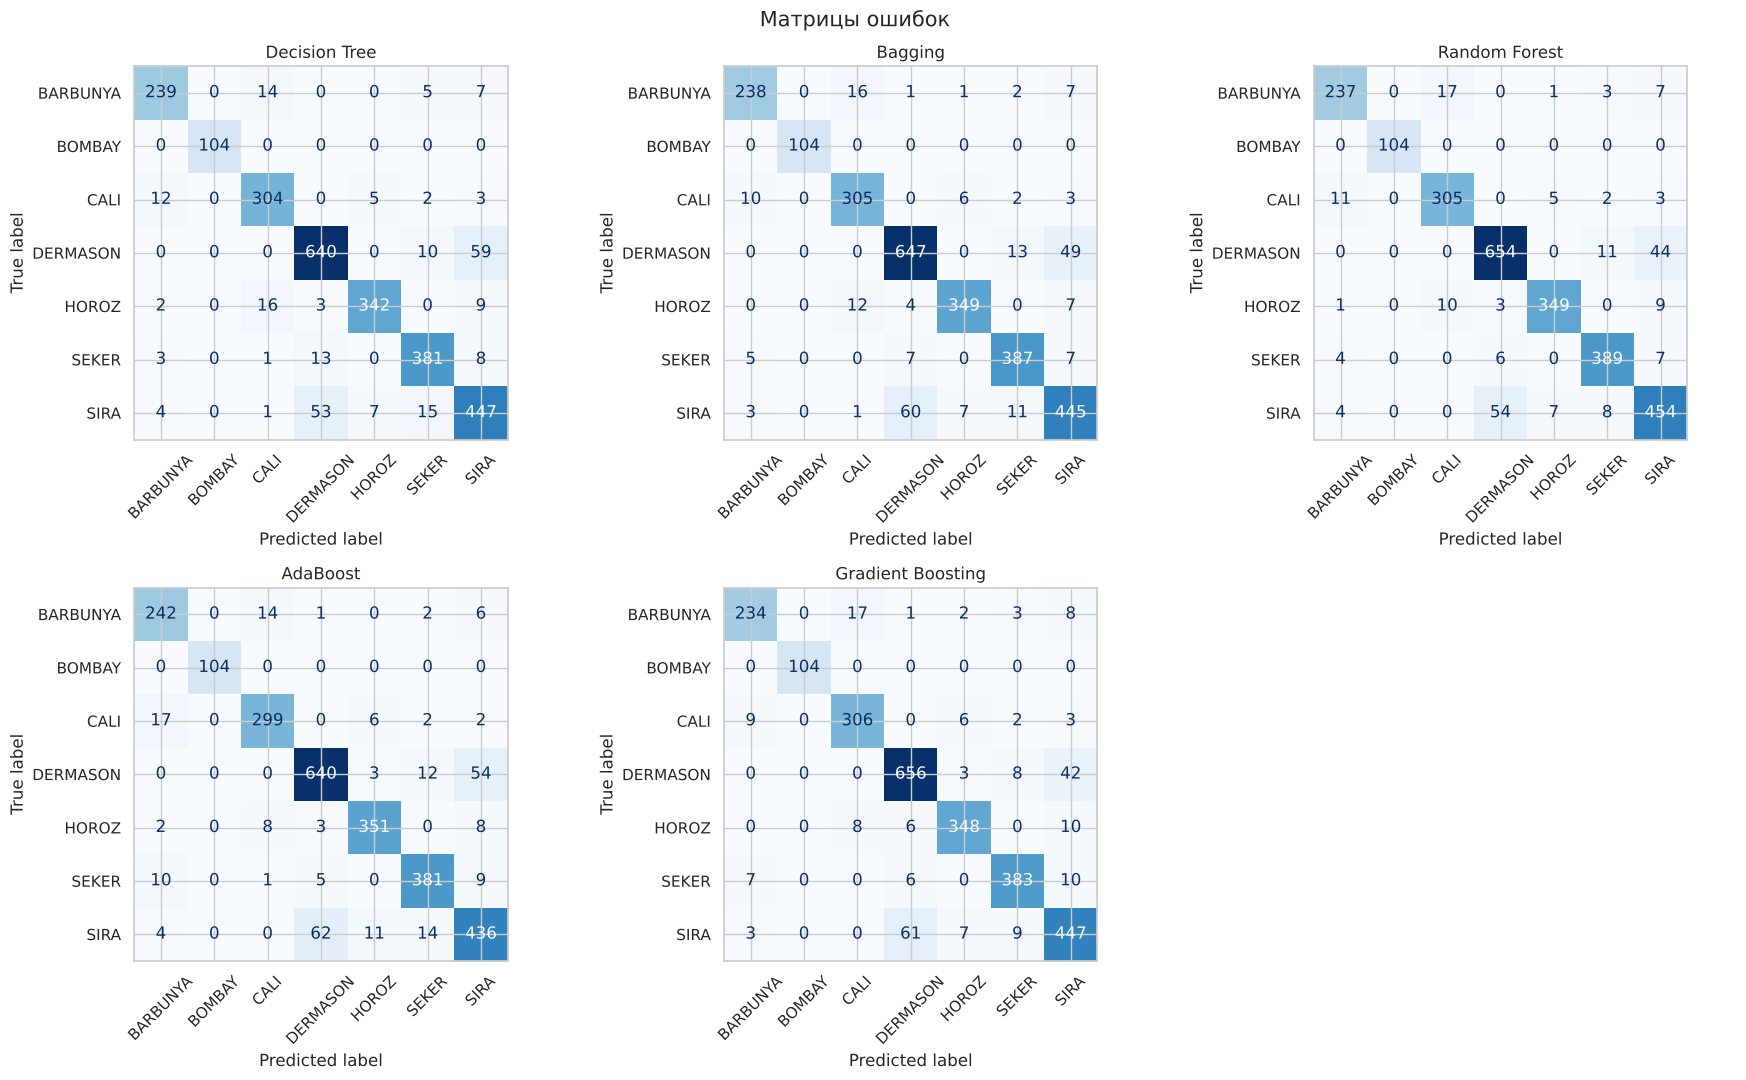

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, n in zip(axes.ravel(), preds):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[n]), display_labels=le.classes_).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
    ax.set_title(n)
axes.ravel()[-1].axis('off'); plt.suptitle('Матрицы ошибок', fontsize=15); save('cm')

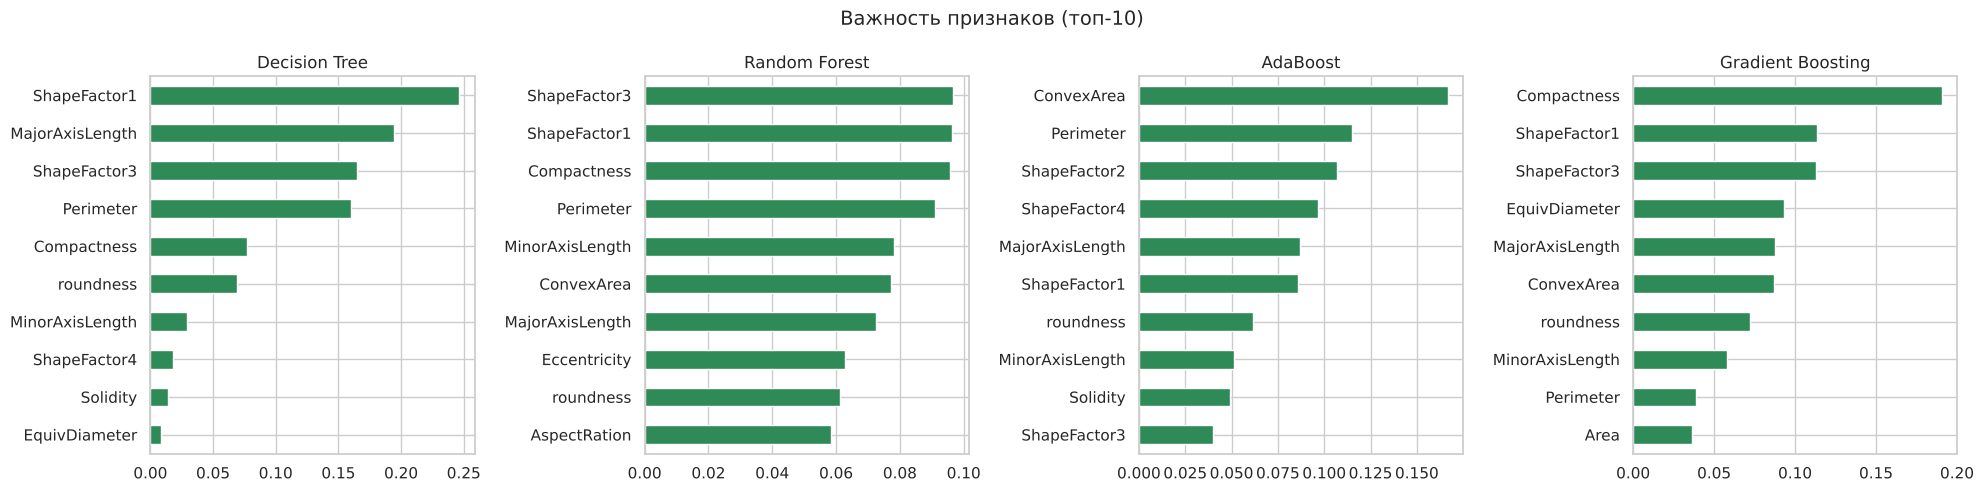

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, n in zip(axes, ['Decision Tree', 'Random Forest', 'AdaBoost', 'Gradient Boosting']):
    pd.Series(models[n].feature_importances_, index=num_cols).sort_values().tail(10).plot.barh(ax=ax, color='seagreen'); ax.set_title(n)
plt.suptitle('Важность признаков (топ-10)', fontsize=14); save('fi')

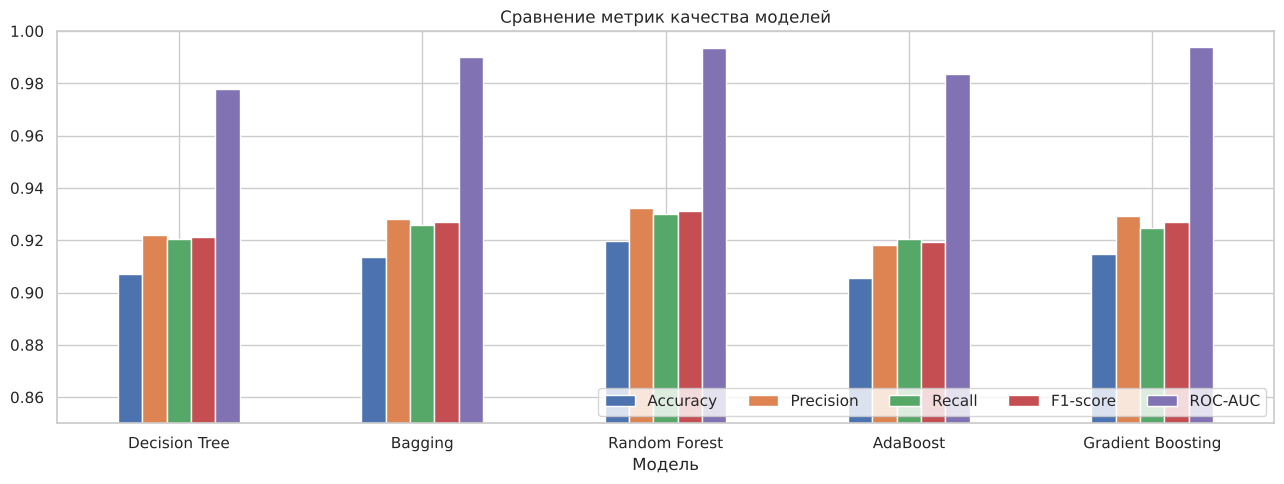

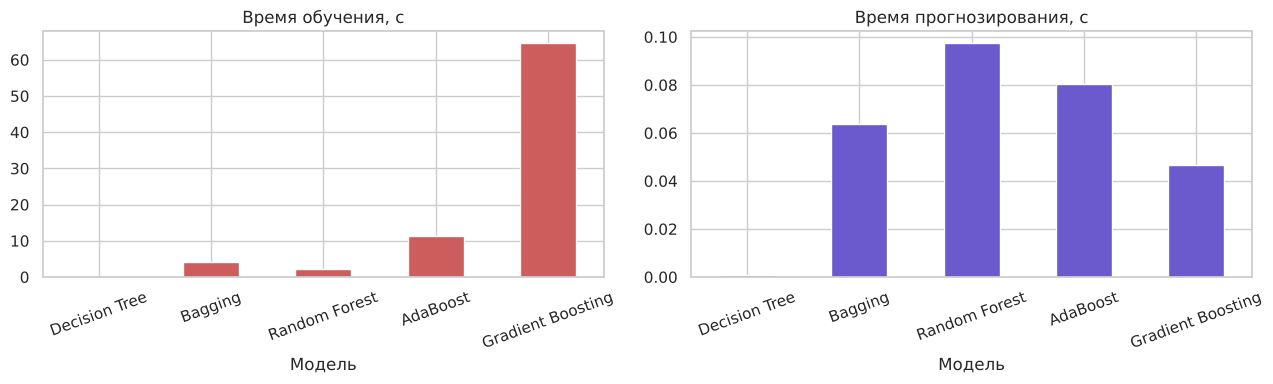

In [19]:
m = res[['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']]
ax = m.plot.bar(figsize=(13, 5), ylim=(0.85, 1.0), rot=0); ax.set_title('Сравнение метрик качества моделей'); ax.legend(loc='lower right', ncol=5)
save('metrics')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
res['Обучение, с'].plot.bar(ax=ax[0], color='indianred', rot=20); ax[0].set_title('Время обучения, с')
res['Прогноз, с'].plot.bar(ax=ax[1], color='slateblue', rot=20); ax[1].set_title('Время прогнозирования, с'); save('time')

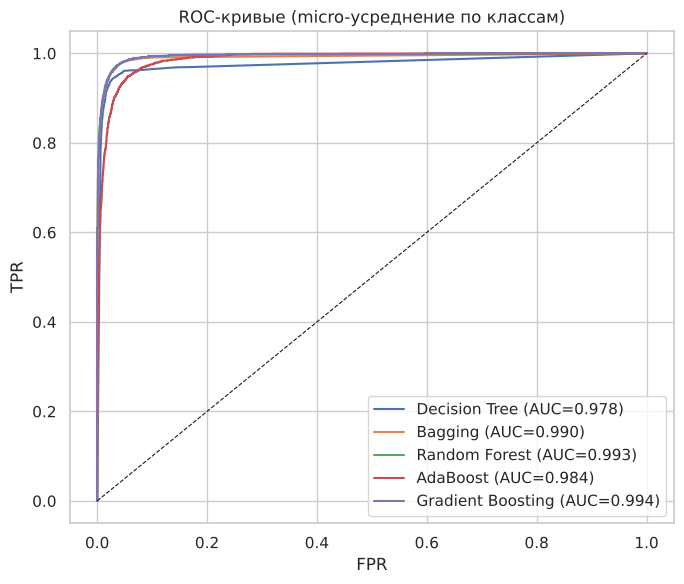

In [20]:
from sklearn.metrics import roc_curve
yb = label_binarize(y_test, classes=range(len(le.classes_)))
plt.figure(figsize=(7, 6))
for n in preds:
    fpr, tpr, _ = roc_curve(yb.ravel(), probas[n].ravel()); plt.plot(fpr, tpr, label=f"{n} (AUC={res.loc[n, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', lw=0.8); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC-кривые (micro-усреднение по классам)'); plt.legend(); save('roc')

## Этап 8. Сравнение моделей

In [21]:
best = res['F1-score'].idxmax()
print('Лучшая модель по F1 (macro):', best)
print('Прирост F1 лучшего ансамбля относительно Decision Tree:', round(res.loc[best, 'F1-score'] - res.loc['Decision Tree', 'F1-score'], 4))
print(res[['Accuracy', 'F1-score', 'Обучение, с']].sort_values('F1-score', ascending=False).round(4))

Лучшая модель по F1 (macro): Random Forest
Прирост F1 лучшего ансамбля относительно Decision Tree: 0.0099
                   Accuracy  F1-score  Обучение, с
Модель                                            
Random Forest        0.9199    0.9310       2.2905
Gradient Boosting    0.9147    0.9269      64.6294
Bagging              0.9136    0.9269       4.1975
Decision Tree        0.9070    0.9211       0.1370
AdaBoost             0.9055    0.9193      11.2826
